In [67]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline
pd.set_option('display.max_columns', None)

df = pd.read_csv("Sample - Superstore.csv",encoding='latin1')

In [68]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [69]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [71]:
df.shape

(9994, 21)

In [72]:
num = df[["Sales", "Quantity", "Discount", "Profit", 'Order Date', 'Ship Date']]
num2 = df[["Sales", "Quantity", "Discount", "Profit"]]
cat = df[['Row ID', 'Order ID', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment','Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']]

In [73]:
round(num.describe(), 3)

,Sales,Quantity,Discount,Profit
count,9994.000,9994.000,9994.000,9994.000
mean,229.858,3.790,0.156,28.657
std,623.245,2.225,0.206,234.260
min,0.444,1.000,0.000,-6599.978
25%,17.280,2.000,0.000,1.729
50%,54.490,3.000,0.200,8.666
75%,209.940,5.000,0.200,29.364
max,22638.480,14.000,0.800,8399.976


In [74]:
frequency_table = cat.value_counts()
frequency_table

Row ID  Order ID        Ship Mode       Customer ID  Customer Name     Segment      Country        City         State          Postal Code  Region   Product ID       Category         Sub-Category  Product Name                                                               Sales    Quantity  Discount  Profit   
1       CA-2016-152156  Second Class    CG-12520     Claire Gute       Consumer     United States  Henderson    Kentucky       42420        South    FUR-BO-10001798  Furniture        Bookcases     Bush Somerset Collection Bookcase                                          261.960  2         0.0        41.9136     1
6666    CA-2016-115483  Second Class    JS-15880     John Stevenson    Consumer     United States  Irving       Texas          75061        Central  OFF-PA-10001497  Office Supplies  Paper         Xerox 1914                                                                 219.840  5         0.2        79.6920     1
6659    CA-2017-135937  Standard Class  KM-16375     Kath

In [75]:
round(num.describe().T, 2)

,count,mean,std,min,25%,50%,75%,max
Sales,9994.0,229.86,623.25,0.44,17.28,54.49,209.94,22638.48
Quantity,9994.0,3.79,2.23,1.00,2.00,3.00,5.00,14.00
Discount,9994.0,0.16,0.21,0.00,0.00,0.20,0.20,0.80
Profit,9994.0,28.66,234.26,-6599.98,1.73,8.67,29.36,8399.98


In [76]:
cat.head()

,Row ID,Order ID,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [77]:
segment = cat['Segment']
category = cat['Category']
ship = cat['Ship Mode']
subcat = cat['Sub-Category']
region = cat['Region']
segment.unique()


array(['Consumer', 'Corporate', 'Home Office'], dtype=object)

In [78]:
ship.unique()

array(['Second Class', 'Standard Class', 'First Class', 'Same Day'],
      dtype=object)

In [79]:
segment.value_counts()

Segment
Consumer       5191
Corporate      3020
Home Office    1783
Name: count, dtype: int64

In [80]:
cat.Region.value_counts()

Region
West       3203
East       2848
Central    2323
South      1620
Name: count, dtype: int64

In [81]:
category.value_counts()

Category
Office Supplies    6026
Furniture          2121
Technology         1847
Name: count, dtype: int64

In [82]:
cat.City.value_counts()

City
New York City      915
Los Angeles        747
Philadelphia       537
San Francisco      510
Seattle            428
                  ... 
Glenview             1
Missouri City        1
Rochester Hills      1
Palatine             1
Manhattan            1
Name: count, Length: 531, dtype: int64

In [83]:
subcat.value_counts()

Sub-Category
Binders        1523
Paper          1370
Furnishings     957
Phones          889
Storage         846
Art             796
Accessories     775
Chairs          617
Appliances      466
Labels          364
Tables          319
Envelopes       254
Bookcases       228
Fasteners       217
Supplies        190
Machines        115
Copiers          68
Name: count, dtype: int64

In [84]:
crosstab_result = pd.crosstab(segment, ship)
crosstab_result

Ship Mode,First Class,Same Day,Second Class,Standard Class
Segment,,,,
Consumer,769,317,1020,3085
Corporate,485,114,609,1812
Home Office,284,112,316,1071


In [85]:
crosstab_result2 = pd.crosstab(segment, category)
crosstab_result2

Category,Furniture,Office Supplies,Technology
Segment,,,
Consumer,1113,3127,951
Corporate,646,1820,554
Home Office,362,1079,342


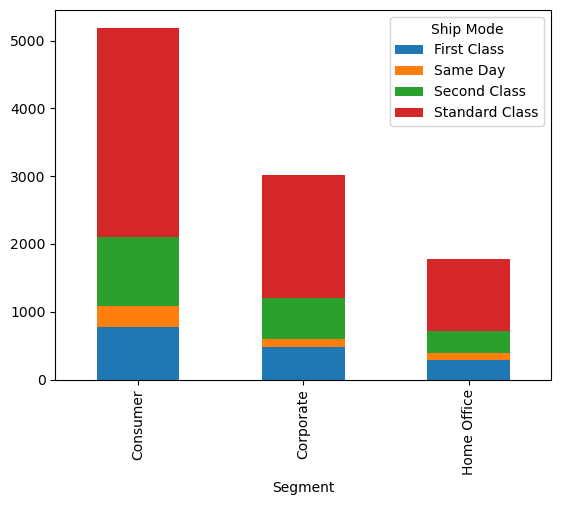

In [86]:
crosstab_result.plot(kind='bar', stacked=True)
plt.show()

In [87]:
top10 = df.City.value_counts().head(10).index
df_top10 = df[df.City.isin(top10)]

C:\Users\Asus\AppData\Local\Temp\ipykernel_17532\2711778775.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


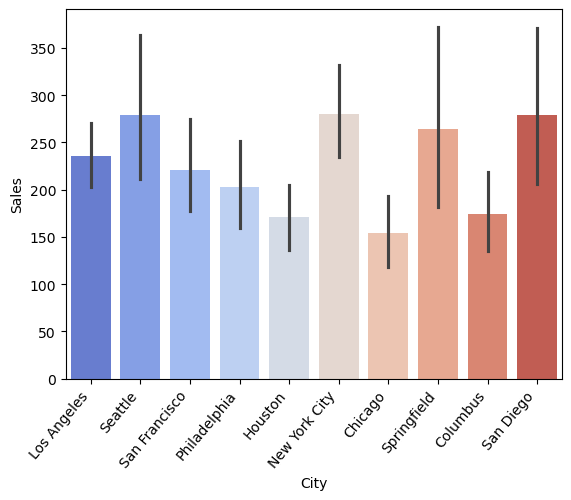

In [88]:
sns.barplot(
    data=df_top10, 
    x="City", 
    y="Sales", 
    estimator='mean', 
    palette="coolwarm"
 )
plt.xticks(rotation=50, ha='right')
plt.show()

C:\Users\Asus\AppData\Local\Temp\ipykernel_17532\1680046605.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


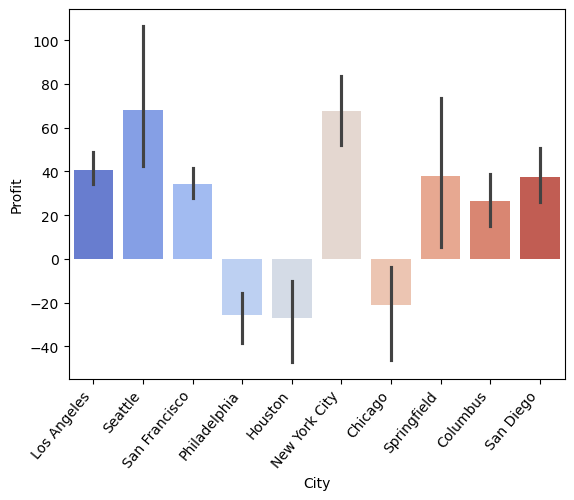

In [89]:
sns.barplot(
    data=df_top10, 
    x="City", 
    y="Profit", 
    estimator='mean', 
    palette="coolwarm"
 )
plt.xticks(rotation=50, ha='right')
plt.show()

In [90]:
df.groupby("Segment")["Profit"].mean()

Segment
Consumer       25.836873
Corporate      30.456667
Home Office    33.818664
Name: Profit, dtype: float64

In [91]:
df.groupby("Segment")["Sales"].mean()

Segment
Consumer       223.733644
Corporate      233.823300
Home Office    240.972041
Name: Sales, dtype: float64

In [92]:
df.groupby("Segment")["Quantity"].mean()

Segment
Consumer       3.760547
Corporate      3.843709
Home Office    3.782389
Name: Quantity, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

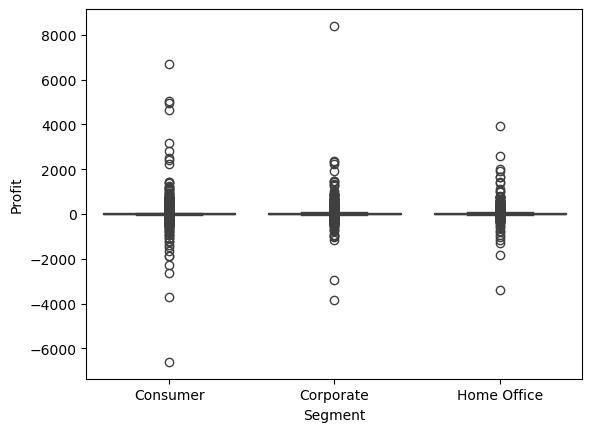

In [93]:
sns.boxplot(
    data=df,
    x='Segment',
    y='Profit',
    )
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

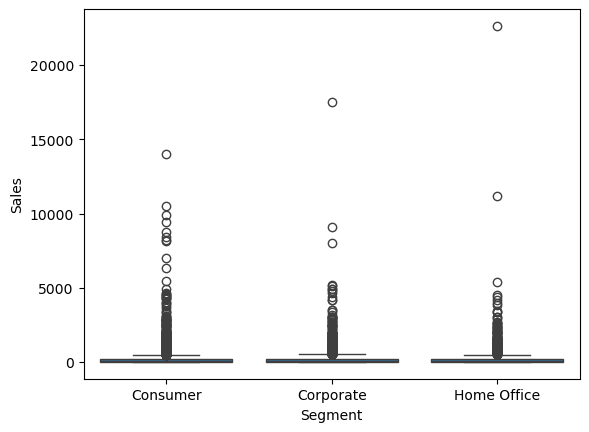

In [94]:
sns.boxplot(
    data=df,
    x='Segment',
    y='Sales',
    )
plt.show

In [95]:
df.groupby("City")["Profit"].sum().sort_values(ascending=False).head(20)

City
New York City    62036.9837
Los Angeles      30440.7579
Seattle          29156.0967
San Francisco    17507.3854
Detroit          13181.7908
Lafayette        10018.3876
Jackson           7581.6828
Atlanta           6993.6629
Minneapolis       6824.5846
San Diego         6377.1960
Springfield       6200.6974
Columbus          5897.1013
Newark            5793.7588
Columbia          5606.1167
Richmond          5567.2486
Providence        5505.6569
Henderson         4911.8609
Arlington         4169.6969
Lakewood          3234.0278
Milwaukee         2793.0851
Name: Profit, dtype: float64

In [96]:
df.groupby("City")["Profit"].sum().sort_values(ascending=True).head(20)

City
Philadelphia       -13837.7674
Houston            -10153.5485
San Antonio         -7299.0502
Lancaster           -7239.0684
Chicago             -6654.5688
Burlington          -3622.8772
Dallas              -2846.5257
Phoenix             -2790.8832
Aurora              -2691.7386
Jacksonville        -2323.8350
Memphis             -1479.0400
Louisville          -1430.3129
Medina              -1343.0446
Round Rock          -1183.4313
Knoxville           -1165.0755
Miami               -1150.3704
Rockford            -1149.5078
Clarksville         -1055.3532
Bethlehem           -1003.0958
Colorado Springs     -956.6841
Name: Profit, dtype: float64

In [97]:
num2.corr()

,Sales,Quantity,Discount,Profit
Sales,1.000000,0.200795,-0.028190,0.479064
Quantity,0.200795,1.000000,0.008623,0.066253
Discount,-0.028190,0.008623,1.000000,-0.219487
Profit,0.479064,0.066253,-0.219487,1.000000


In [98]:
num.columns

Index(['Sales', 'Quantity', 'Discount', 'Profit', 'Order Date', 'Ship Date'], dtype='object')

In [99]:
round(float(df["Discount"].corr(df["Sales"], method="pearson")), 2)

-0.03

In [100]:
df["Discount"].corr(df["Sales"], method="spearman")

np.float64(-0.05696855074893833)

In [101]:
round(float(df["Discount"].corr(df["Sales"], method="spearman")), 2)

-0.06

- **Pearson Correlation**: \(-0.03\)
- **Spearman Correlation**: \(*-0.06\)

**Insights:**

- The **Pearson correlation** of \(-0.03\) suggests a weak linear relationship between the sales of a category and its discount. There's no lineair correlation. 
  
- The **Spearman correlation** of \(-0.06\) indicates a weak monotonic relationship between the two variables. There's no correlation within these two variables. 

Both values are close to 0, which means that the hight of the discount is barely influencing the sales. 

In [102]:
num2.corrwith(num2["Sales"], method="spearman").sort_values(ascending=False)

Sales       1.000000
Profit      0.518407
Quantity    0.327426
Discount   -0.056969
dtype: float64

In [103]:
num2.corr()

,Sales,Quantity,Discount,Profit
Sales,1.000000,0.200795,-0.028190,0.479064
Quantity,0.200795,1.000000,0.008623,0.066253
Discount,-0.028190,0.008623,1.000000,-0.219487
Profit,0.479064,0.066253,-0.219487,1.000000


In [104]:
correlation_matrix = num2.corr()

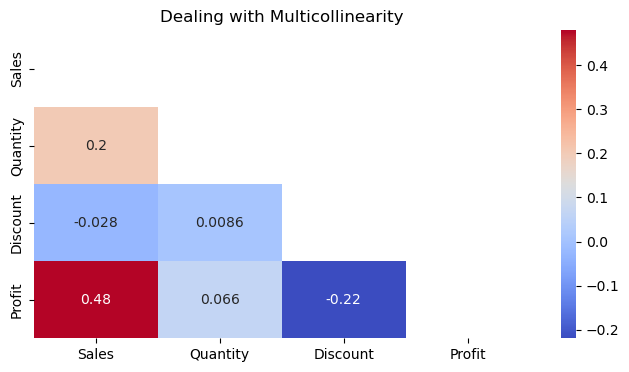

In [105]:
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
plt.figure(figsize=(8, 4))
sns.heatmap(correlation_matrix, mask=mask, annot=True, cmap="coolwarm")

plt.title("Dealing with Multicollinearity")
plt.show()

In [106]:
print(category.value_counts())
print(subcat.value_counts())

Category
Office Supplies    6026
Furniture          2121
Technology         1847
Name: count, dtype: int64
Sub-Category
Binders        1523
Paper          1370
Furnishings     957
Phones          889
Storage         846
Art             796
Accessories     775
Chairs          617
Appliances      466
Labels          364
Tables          319
Envelopes       254
Bookcases       228
Fasteners       217
Supplies        190
Machines        115
Copiers          68
Name: count, dtype: int64


In [107]:
category_discount_profit_corr = df.groupby("Sub-Category").apply(
    lambda x: x["Discount"].corr(x["Profit"])).sort_values(ascending=True)
print(category_discount_profit_corr)

Sub-Category
Tables        -0.671770
Bookcases     -0.607067
Chairs        -0.591815
Machines      -0.582508
Appliances    -0.495198
Furnishings   -0.471598
Phones        -0.469341
Storage       -0.364029
Copiers       -0.356122
Supplies      -0.253066
Art           -0.251636
Accessories   -0.244192
Binders       -0.238195
Envelopes     -0.184235
Paper         -0.172494
Fasteners     -0.171133
Labels        -0.132661
dtype: float64


C:\Users\Asus\AppData\Local\Temp\ipykernel_17532\2370201466.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  category_discount_profit_corr = df.groupby("Sub-Category").apply(


<function matplotlib.pyplot.show(close=None, block=None)>

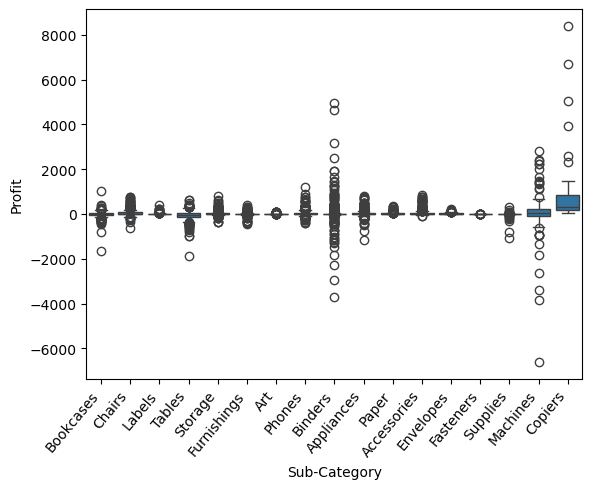

In [108]:
sns.boxplot(
    data=df,
    x='Sub-Category',
    y='Profit',
    )
plt.xticks(rotation=50, ha='right')
plt.show

In [109]:
subcat_neg = df[df["Sub-Category"].isin(["Bookcases", "Tables"])]
round(float(subcat_neg["Discount"].corr(subcat_neg["Profit"], method="pearson")), 2)

-0.64

In [110]:
subcat_neg = df[df["Sub-Category"].isin(["Bookcases", "Tables"])]

subcat_neg_corr = subcat_neg.groupby("Sub-Category").apply(
    lambda x: pd.Series({
        "pearson": x["Discount"].corr(x["Profit"], method="pearson"),
        "spearman": x["Discount"].corr(x["Profit"], method="spearman")
    })
).round(2)

print(subcat_neg_corr)

              pearson  spearman
Sub-Category                   
Bookcases       -0.61     -0.83
Tables          -0.67     -0.86


C:\Users\Asus\AppData\Local\Temp\ipykernel_17532\2017441512.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  subcat_neg_corr = subcat_neg.groupby("Sub-Category").apply(


In [111]:
for cat in ["Bookcases", "Tables"]:
    subset = df[df["Sub-Category"] == cat]
    pearson = round(subset["Discount"].corr(subset["Profit"], method="pearson"), 2)
    spearman = round(subset["Discount"].corr(subset["Profit"], method="spearman"), 2)
    print(f"{cat}: Pearson = {pearson}, Spearman = {spearman}")
    

Bookcases: Pearson = -0.61, Spearman = -0.83
Tables: Pearson = -0.67, Spearman = -0.86


- **Pearson Correlation**: \(-0.61\)
- **Spearman Correlation**: \(-0.83\)

**Insights:**

- The **Pearson correlation** of \(-0.61\) suggests a strong negative linear relationship between the profit of a Bookcases and its discount. There's a lineair correlation. 
  
- The **Spearman correlation** of \(-0.83\) indicates a strong negative monotonic relationship between the two variables. There's a correlation within these two variables. 

Spearman correlation is highest and close to -1, which means that the hight of the discount is negatively influencing the profit. The correlation is not lineair, which could indicate that lower discounts are still profitable. Higher discount appear to be less profitable. 

In [112]:
for cat in ["Bookcases", "Tables"]:
    subset = df[df["Sub-Category"] == cat]
    pearson = round(subset["Discount"].corr(subset["Sales"], method="pearson"), 2)
    spearman = round(subset["Discount"].corr(subset["Sales"], method="spearman"), 2)
    print(f"{cat}: Pearson = {pearson}, Spearman = {spearman}")

Bookcases: Pearson = -0.12, Spearman = -0.15
Tables: Pearson = -0.3, Spearman = -0.28


In [113]:
top_selling_subcategories = df.groupby("Sub-Category")["Quantity"].sum().sort_values(ascending=False)
print(top_selling_subcategories)

Sub-Category
Binders        5974
Paper          5178
Furnishings    3563
Phones         3289
Storage        3158
Art            3000
Accessories    2976
Chairs         2356
Appliances     1729
Labels         1400
Tables         1241
Fasteners       914
Envelopes       906
Bookcases       868
Supplies        647
Machines        440
Copiers         234
Name: Quantity, dtype: int64


<function matplotlib.pyplot.show(close=None, block=None)>

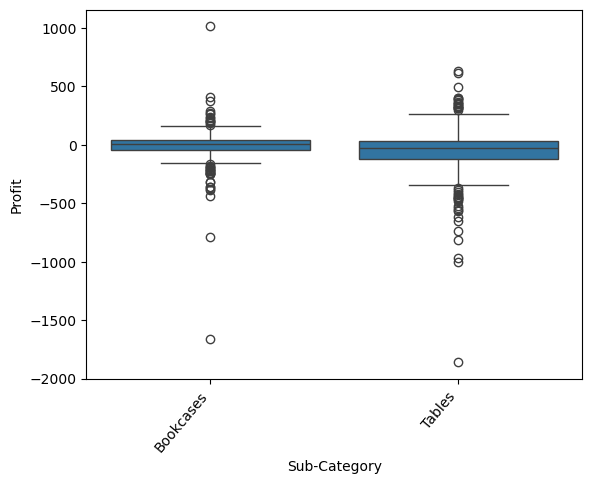

In [114]:
sns.boxplot(
    data=subcat_neg,
    x='Sub-Category',
    y='Profit',
    )
plt.xticks(rotation=50, ha='right')
plt.show

C:\Users\Asus\AppData\Local\Temp\ipykernel_17532\1756301754.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Sub-Category", y="Sales", palette="coolwarm", errorbar=None)


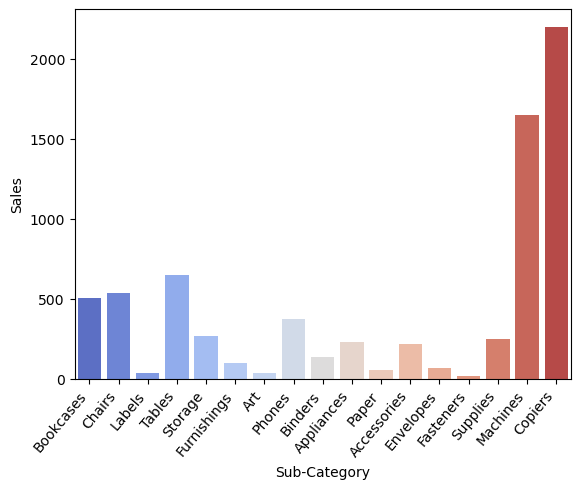

In [115]:
sns.barplot(data=df, x="Sub-Category", y="Sales", palette="coolwarm", errorbar=None)
plt.xticks(rotation=50, ha='right')
plt.show()

C:\Users\Asus\AppData\Local\Temp\ipykernel_17532\894897767.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Sub-Category", y="Profit", palette="coolwarm", errorbar=None)


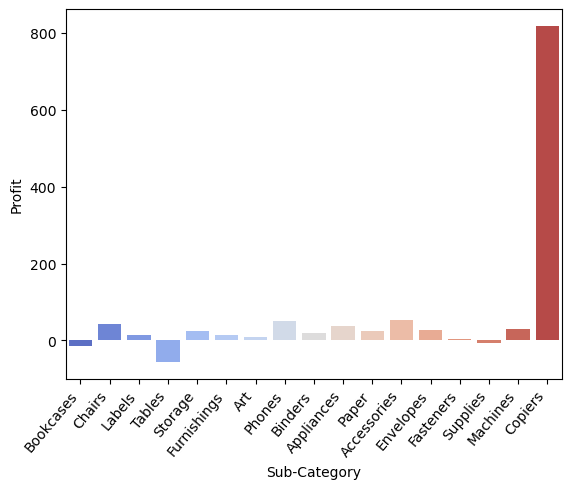

In [116]:
sns.barplot(data=df, x="Sub-Category", y="Profit", palette="coolwarm", errorbar=None)
plt.xticks(rotation=50, ha='right')
plt.show()

C:\Users\Asus\AppData\Local\Temp\ipykernel_17532\3092767477.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Sub-Category", y="Quantity", palette="coolwarm", errorbar=None)


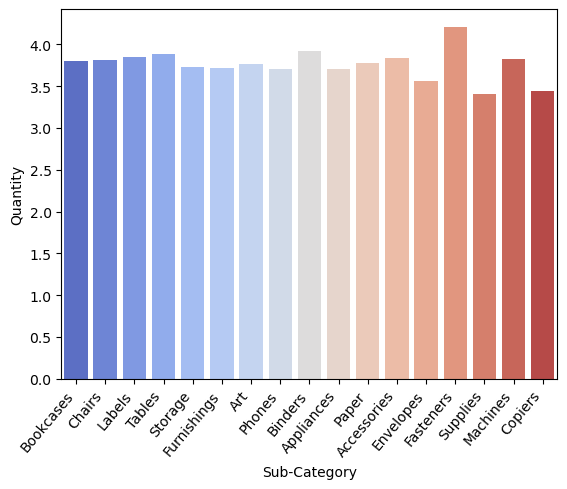

In [117]:
sns.barplot(data=df, x="Sub-Category", y="Quantity", palette="coolwarm", errorbar=None)
plt.xticks(rotation=50, ha='right')
plt.show()

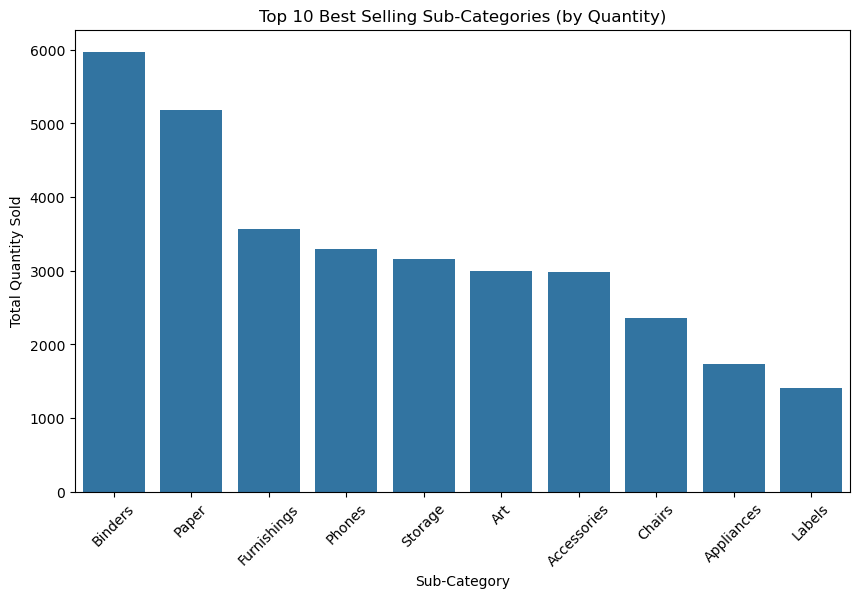

In [118]:
top_selling_subcategories = top_selling_subcategories.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_selling_subcategories.index, y=top_selling_subcategories.values)
plt.title("Top 10 Best Selling Sub-Categories (by Quantity)")
plt.xlabel("Sub-Category")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=45)
plt.show()

In [119]:
subset = df[df["Sub-Category"] == "Binders"]

top_selling_binder = subset.groupby("Product Name")["Quantity"].sum().sort_values(ascending=False).head(10)
print(top_selling_binder)

Product Name
Avery Non-Stick Binders                                       71
Storex Dura Pro Binders                                       71
GBC Premium Transparent Covers with Diagonal Lined Pattern    67
Wilson Jones Turn Tabs Binder Tool for Ring Binders           59
GBC Standard Recycled Report Covers, Clear Plastic Sheets     51
Avery Durable Binders                                         50
GBC DocuBind P50 Personal Binding Machine                     50
GBC Instant Report Kit                                        50
Wilson Jones Easy Flow II Sheet Lifters                       49
Pressboard Hanging Data Binders for Unburst Sheets            48
Name: Quantity, dtype: int64


In [120]:
top10_sellingproducts_overall = df.groupby("Product Name")["Quantity"].sum().sort_values(ascending=False).head(10)
print(top10_sellingproducts_overall)

Product Name
Staples                                                       215
Staple envelope                                               170
Easy-staple paper                                             150
Staples in misc. colors                                        86
KI Adjustable-Height Table                                     74
Avery Non-Stick Binders                                        71
Storex Dura Pro Binders                                        71
GBC Premium Transparent Covers with Diagonal Lined Pattern     67
Situations Contoured Folding Chairs, 4/Set                     64
Staple-based wall hangings                                     62
Name: Quantity, dtype: int64


In [121]:
top10_salesproducts_overall = df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10)
print(top10_salesproducts_overall)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


In [122]:
top_sales_binder = subset.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10)
print(top_sales_binder)

Product Name
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
GBC DocuBind P400 Electric Binding System                                      17965.068
Ibico EPK-21 Electric Binding System                                           15875.916
Fellowes PB300 Plastic Comb Binding Machine                                     8070.192
Ibico Ibimaster 300 Manual Binding System                                       7985.383
GBC DocuBind 300 Electric Binding Machine                                       6785.142
Ibico Hi-Tech Manual Binding System                                             5398.323
GBC DocuBind TL200 Manual Binding Machine                                       4322.814
Name: Sales, dtype: float64


In [123]:
top_profit_binder = subset.groupby("Product Name")["Profit"].sum().sort_values(ascending=False).head(10)
print(top_profit_binder)

Product Name
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    7753.0390
Ibico EPK-21 Electric Binding System                                           3345.2823
Fellowes PB300 Plastic Comb Binding Machine                                    2518.0551
Ibico Ibimaster 300 Manual Binding System                                      2318.3370
GBC DocuBind TL300 Electric Binding System                                     2233.5051
GBC DocuBind TL200 Manual Binding Machine                                      1592.4978
Ibico EB-19 Dual Function Manual Binding System                                1086.3772
GBC DocuBind 200 Manual Binding Machine                                        1052.4500
GBC Ibimaster 500 Manual ProClick Binding System                                760.9800
Fellowes PB200 Plastic Comb Binding Machine                                     693.5592
Name: Profit, dtype: float64


In [124]:
top10_profitproducts_overall = df.groupby("Product Name")["Profit"].sum().sort_values(ascending=False).head(10)
print(top10_profitproducts_overall)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.0390
Hewlett Packard LaserJet 3310 Copier                                            6983.8836
Canon PC1060 Personal Laser Copier                                              4570.9347
HP Designjet T520 Inkjet Large Format Printer - 24" Color                       4094.9766
Ativa V4110MDD Micro-Cut Shredder                                               3772.9461
3D Systems Cube Printer, 2nd Generation, Magenta                                3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System                      3696.2820
Ibico EPK-21 Electric Binding System                                            3345.2823
Zebra ZM400 Thermal Label Printer                                               3343.5360
Name: Profit, dtype: float64


In [125]:
worst_profit_binder = subset.groupby("Product Name")["Profit"].sum().sort_values(ascending=True).head(10)
print(worst_profit_binder)

Product Name
GBC DocuBind P400 Electric Binding System                          -1878.1662
GBC ProClick 150 Presentation Binding System                        -461.3308
GBC VeloBinder Electric Binding Machine                             -411.3320
Ibico Hi-Tech Manual Binding System                                 -304.9900
Catalog Binders with Expanding Posts                                -242.2080
Premier Elliptical Ring Binder, Black                               -201.5128
Acco D-Ring Binder w/DublLock                                       -102.8378
GBC Linen Binding Covers                                             -82.4068
Wilson Jones Elliptical Ring 3 1/2" Capacity Binders, 800 sheets     -82.1760
Avery Recycled Flexi-View Covers for Binding Systems                 -69.5702
Name: Profit, dtype: float64


In [126]:
worst_profitproducts_overall = df.groupby("Product Name")["Profit"].sum().sort_values(ascending=True).head(10)
print(worst_profitproducts_overall)

Product Name
Cubify CubeX 3D Printer Double Head Print                           -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                           -4589.9730
Cubify CubeX 3D Printer Triple Head Print                           -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases            -2876.1156
Bush Advantage Collection Racetrack Conference Table                -1934.3976
GBC DocuBind P400 Electric Binding System                           -1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit               -1811.0784
Martin Yale Chadless Opener Electric Letter Opener                  -1299.1836
Balt Solid Wood Round Tables                                        -1201.0581
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables   -1148.4375
Name: Profit, dtype: float64


In [127]:
worst_selling_binder = subset.groupby("Product Name")["Quantity"].sum().sort_values(ascending=True).head(10)
print(worst_selling_binder)

Product Name
Wilson Jones Hanging Recycled Pressboard Data Binders    4
Wilson Jones DublLock D-Ring Binders                     6
Acco Economy Flexible Poly Round Ring Binder             6
Wilson Jones Suede Grain Vinyl Binders                   8
Avery Binder Labels                                      8
Ibico Recycled Grain-Textured Covers                     8
Pressboard Data Binder, Crimson, 12" X 8 1/2"            9
Mead 1st Gear 2" Zipper Binder, Asst. Colors             9
Recycled Premium Regency Composition Covers              9
Storex Flexible Poly Binders with Double Pockets         9
Name: Quantity, dtype: int64


In [128]:
worst_sellingproducts_overall = df.groupby("Product Name")["Quantity"].sum().sort_values(ascending=True).head(10)
print(worst_sellingproducts_overall)

Product Name
Boston 1900 Electric Pencil Sharpener                                        1
Bush Saratoga Collection 5-Shelf Bookcase, Hanover Cherry, *Special Order    1
Penpower WorldCard Pro Card Scanner                                          1
Global Enterprise Series Seating Low-Back Swivel/Tilt Chairs                 1
Xerox 20                                                                     1
Eureka Disposable Bags for Sanitaire Vibra Groomer I Upright Vac             2
Canon imageCLASS MF7460 Monochrome Digital Laser Multifunction Copier        2
Xerox 1989                                                                   2
NeatDesk Desktop Scanner & Digital Filing System                             2
RCA ViSYS 25423RE1 Corded phone                                              2
Name: Quantity, dtype: int64


In [129]:
newyork = df[df["City"] == "New York City"]

top_sp_nyc = newyork.groupby("Product Name")["Quantity"].sum().sort_values(ascending=False).head(10)
print(top_sp_nyc)

Product Name
Staple envelope                                               28
Easy-staple paper                                             19
Dual Level, Single-Width Filing Carts                         19
Storex Dura Pro Binders                                       18
GBC Premium Transparent Covers with Diagonal Lined Pattern    18
Dixon Prang Watercolor Pencils, 10-Color Set with Brush       18
Cardinal HOLDit! Binder Insert Strips,Extra Strips            17
Lock-Up Easel 'Spel-Binder'                                   16
Avery 485                                                     15
Fiskars Softgrip Scissors                                     15
Name: Quantity, dtype: int64


In [130]:
profit_sp_nyc = newyork.groupby("Product Name")["Profit"].sum().sort_values(ascending=False).head(10)
print(profit_sp_nyc)

Product Name
Canon imageCLASS 2200 Advanced Copier                                    3919.9888
Zebra ZM400 Thermal Label Printer                                        3343.5360
HP Designjet T520 Inkjet Large Format Printer - 24" Color                2239.9872
Canon imageCLASS MF7460 Monochrome Digital Laser Multifunction Copier    1995.9900
Hewlett-Packard Desktjet 6988DT Refurbished Printer                      1668.2050
GBC DocuBind TL300 Electric Binding System                               1453.1238
GBC DocuBind P400 Electric Binding System                                1415.4296
Ativa V4110MDD Micro-Cut Shredder                                        1371.9804
3D Systems Cube Printer, 2nd Generation, Magenta                         1351.9896
Bady BDG101FRU Card Printer                                              1159.9855
Name: Profit, dtype: float64


In [131]:
philly = df[df["City"] == "Philadelphia"]
philly.shape


(537, 21)

In [132]:
topcat_phil = philly.groupby("Sub-Category")["Quantity"].sum().sort_values(ascending=False).head(10)
print(topcat_phil)

Sub-Category
Binders        284
Phones         226
Paper          225
Furnishings    210
Storage        153
Chairs         139
Accessories    137
Art            136
Labels          98
Appliances      74
Name: Quantity, dtype: int64


In [133]:
topprof_phil = philly.groupby("Sub-Category")["Profit"].sum().sort_values(ascending=False).head(10)
print(topprof_phil)

Sub-Category
Copiers        1735.9829
Accessories     895.1663
Appliances      693.5040
Paper           690.5440
Envelopes       351.4146
Furnishings     293.1427
Labels          151.9096
Art             116.4417
Fasteners        29.3222
Storage       -1163.9182
Name: Profit, dtype: float64


In [134]:
worstprof_phil = philly.groupby("Sub-Category")["Profit"].sum().sort_values(ascending=True).head(10)
print(worstprof_phil)

Sub-Category
Phones      -3555.0398
Binders     -3385.2340
Tables      -2588.7538
Bookcases   -2568.1413
Machines    -2219.2456
Chairs      -1963.3730
Supplies    -1351.4897
Storage     -1163.9182
Fasteners      29.3222
Art           116.4417
Name: Profit, dtype: float64


In [135]:
customer_summary = df.groupby("Customer ID").agg({
    "Quantity": "sum",
    "Discount": "mean",
    "Profit": "sum"
}).reset_index()

In [136]:
quantity_threshold = customer_summary["Quantity"].quantile(0.80)
profit_threshold = customer_summary["Profit"].quantile(0.80)
discount_threshold = customer_summary["Discount"].quantile(0.80)

In [137]:
customer_summary["High_Quantity"] = customer_summary["Quantity"] >= quantity_threshold
customer_summary["High_Profit"] = customer_summary["Profit"] >= profit_threshold
customer_summary["Discount_Seeker"] = customer_summary["Discount"] >= discount_threshold

In [138]:
customer_summary.head(10)

,Customer ID,Quantity,Discount,Profit,High_Quantity,High_Profit,Discount_Seeker
0,AA-10315,30,0.090909,-362.8825,False,False,False
1,AA-10375,41,0.080000,277.3824,False,False,False
2,AA-10480,36,0.016667,435.8274,False,False,False
3,AA-10645,64,0.063889,857.8033,False,True,False
4,AB-10015,13,0.066667,129.3465,False,False,False
5,AB-10060,56,0.044444,2054.5885,False,True,False
6,AB-10105,73,0.240000,5444.8055,True,True,True
7,AB-10150,37,0.133333,313.6597,False,False,False
8,AB-10165,48,0.135714,220.8130,False,False,False
9,AB-10255,39,0.100000,264.5675,False,False,False


In [139]:
print(customer_summary["High_Quantity"].value_counts())
print(customer_summary["High_Profit"].value_counts())
print(customer_summary["Discount_Seeker"].value_counts())

High_Quantity
False    631
True     162
Name: count, dtype: int64
High_Profit
False    634
True     159
Name: count, dtype: int64
Discount_Seeker
False    633
True     160
Name: count, dtype: int64


In [148]:
df_with_labels = df.merge(
    customer_summary[["Customer ID", "High_Quantity", "High_Profit", "Discount_Seeker"]],
    on="Customer ID",
    how="left"
)

df_with_labels.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,High_Quantity,High_Profit,Discount_Seeker
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,False,False,False
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,False,False,False
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,False,False,False
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,False,False,False
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,False,False,False


In [156]:
hq_cust = df_with_labels[df_with_labels["High_Quantity"] == True]
print(hq_cust.head(10))
print(hq_cust.shape)

    Row ID        Order ID  Order Date   Ship Date       Ship Mode  \
5        6  CA-2014-115812    6/9/2014   6/14/2014  Standard Class   
6        7  CA-2014-115812    6/9/2014   6/14/2014  Standard Class   
7        8  CA-2014-115812    6/9/2014   6/14/2014  Standard Class   
8        9  CA-2014-115812    6/9/2014   6/14/2014  Standard Class   
9       10  CA-2014-115812    6/9/2014   6/14/2014  Standard Class   
10      11  CA-2014-115812    6/9/2014   6/14/2014  Standard Class   
11      12  CA-2014-115812    6/9/2014   6/14/2014  Standard Class   
13      14  CA-2016-161389   12/5/2016  12/10/2016  Standard Class   
16      17  CA-2014-105893  11/11/2014  11/18/2014  Standard Class   
21      22  CA-2016-137330   12/9/2016  12/13/2016  Standard Class   

   Customer ID    Customer Name    Segment        Country         City  \
5     BH-11710  Brosina Hoffman   Consumer  United States  Los Angeles   
6     BH-11710  Brosina Hoffman   Consumer  United States  Los Angeles   
7     B

In [157]:
print(hq_cust["City"].value_counts())
print(hq_cust["Sub-Category"].value_counts())


City
New York City    300
Los Angeles      267
Philadelphia     230
San Francisco    167
Seattle          144
                ... 
Miramar            1
Taylor             1
Medford            1
Deer Park          1
Westminster        1
Name: count, Length: 348, dtype: int64
Sub-Category
Binders        540
Paper          477
Furnishings    338
Phones         325
Storage        290
Art            277
Accessories    270
Chairs         219
Appliances     162
Labels         120
Tables         103
Envelopes      102
Fasteners       85
Bookcases       75
Supplies        67
Machines        47
Copiers         18
Name: count, dtype: int64


In [159]:
hp_cust = df_with_labels[df_with_labels["High_Profit"] == True]
print(hp_cust["City"].value_counts())
print(hp_cust["Sub-Category"].value_counts())

City
New York City    269
Los Angeles      202
Seattle          133
San Francisco    125
Houston           99
                ... 
Manhattan          1
Champaign          1
Waterloo           1
Pearland           1
Niagara Falls      1
Name: count, Length: 308, dtype: int64
Sub-Category
Binders        370
Paper          349
Phones         299
Furnishings    233
Storage        221
Accessories    190
Art            185
Chairs         174
Appliances     132
Envelopes       80
Labels          79
Tables          64
Bookcases       49
Supplies        41
Machines        40
Copiers         40
Fasteners       38
Name: count, dtype: int64


In [160]:
ds_cust = df_with_labels[df_with_labels["Discount_Seeker"] == True]
print(ds_cust["City"].value_counts())
print(ds_cust["Sub-Category"].value_counts())

City
Philadelphia     167
Houston          121
Los Angeles      104
New York City    100
Chicago           85
                ... 
Orange             1
Kent               1
Grand Rapids       1
Alexandria         1
Cranston           1
Name: count, Length: 253, dtype: int64
Sub-Category
Binders        395
Paper          222
Furnishings    178
Phones         154
Storage        142
Chairs         126
Accessories    125
Art            113
Appliances      81
Tables          65
Labels          55
Envelopes       48
Bookcases       40
Supplies        39
Fasteners       37
Machines        27
Copiers         15
Name: count, dtype: int64


In [166]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [169]:
# Transform date to numerical types
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

In [171]:
# Calculate delivery time in days
df["Delivery Time"] = (df["Ship Date"] - df["Order Date"]).dt.days
print(df["Delivery Time"].describe())

count    9994.000000
mean        3.958175
std         1.747567
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         7.000000
Name: Delivery Time, dtype: float64


In [172]:
pearson_corr = df["Delivery Time"].corr(df["Quantity"], method="pearson")
spearman_corr = df["Delivery Time"].corr(df["Quantity"], method="spearman")

print(f"Pearson: {round(pearson_corr, 2)}")
print(f"Spearman: {round(spearman_corr, 2)}")

Pearson: 0.02
Spearman: 0.02


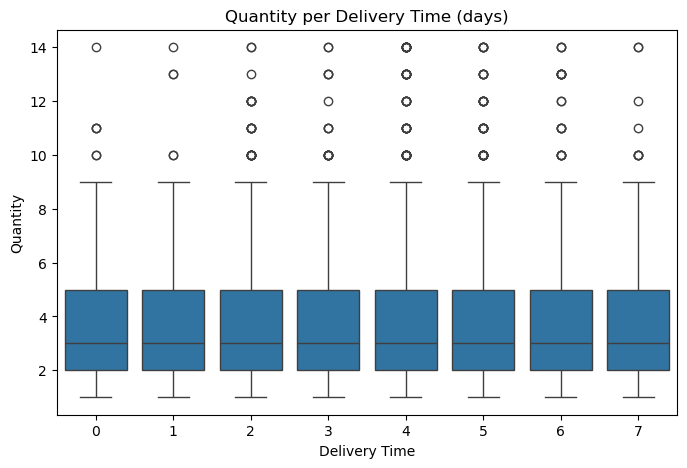

In [173]:
plt.figure(figsize=(8,5))
sns.boxplot(x="Delivery Time", y="Quantity", data=df)
plt.title("Quantity per Delivery Time (days)")
plt.show()

There's no significant relation between the amount of products ordererd and the delivery time. 